<a href="https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/02-tu-primer-modelo-la-recta/clase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Episodio 1.2 · Tu primer modelo: la recta

**Serie:** Del Excel al Machine Learning · **Temporada 1** · 🎬 Video próximamente

## 🎯 Qué vas a aprender

- Mirar la relación entre dos columnas con un **gráfico de dispersión**.
- Trazar la recta que mejor se ajusta a los datos: la **regresión lineal**.
- Leer su pendiente y su punto de corte, y qué tan bien calza con **R²**.
- Reconocer los límites de una recta.

## 📊 En Excel lo harías así

1. Seleccionas dos columnas e insertas un **gráfico de dispersión**.
2. Agregas una **línea de tendencia** y marcas "Presentar ecuación en el gráfico" y "Presentar el valor R cuadrado en el gráfico".
3. O usas fórmulas: `=PENDIENTE()` (`SLOPE`), `=INTERSECCION.EJE()` (`INTERCEPT`), `=COEFICIENTE.R2()` (`RSQ`) y `=PRONOSTICO.LINEAL()` (`FORECAST.LINEAR`).

Sin saberlo, ya estabas haciendo Machine Learning. Hoy lo hacemos en Python, con 6 mil filas.

## 🐍 En Python

### Paso 1: preparar la tabla

Cada venta es una **línea de pedido**: un producto vendido a un cliente. La pregunta es: cuando un cliente pide más líneas en un mes, ¿cómo cambia el monto?

Esta función arma una fila por cliente y mes en que compró. Es una **función lista**: no necesitas memorizarla, solo entender qué entrega.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression

DATOS = "https://raw.githubusercontent.com/PercyTechX/del-excel-al-ml/main/datos/"

In [2]:
def por_cliente_y_mes(ventas):
    """Una fila por cliente y mes en que compró, con sus líneas de pedido y su monto."""
    meses = ventas["fecha"].str[:7]
    return (
        ventas.groupby(["id_cliente", meses])
        .agg(lineas=("total", "size"), total=("total", "sum"))
        .reset_index()
    )

In [3]:
ventas = pd.read_csv(DATOS + "ventas.csv")

mensual = por_cliente_y_mes(ventas)

print(mensual.shape)
mensual.head()

(6459, 4)


,id_cliente,fecha,lineas,total
0,C0001,2024-01,2,252.8
1,C0001,2024-02,3,297.0
2,C0001,2024-04,3,316.0
3,C0001,2024-05,5,1009.0
4,C0001,2024-06,1,92.0


### Paso 2: el gráfico de dispersión

Cada punto es un cliente en un mes. `kind="scatter"` dibuja la dispersión, y necesita decirle qué columna va en cada eje. `alpha=0.2` hace los puntos transparentes: donde se ven más oscuros, hay más casos.

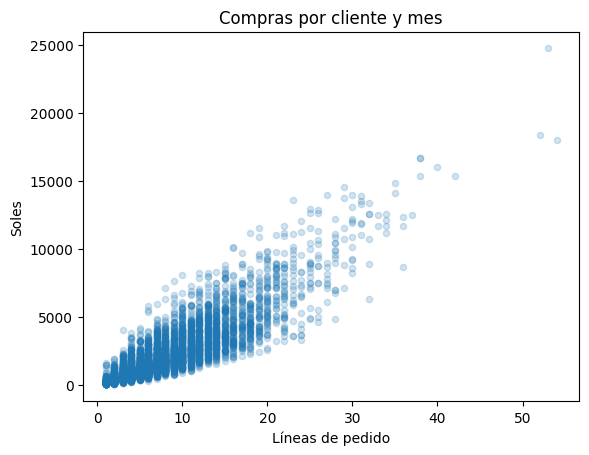

In [4]:
mensual.plot(
    kind="scatter",
    x="lineas",
    y="total",
    alpha=0.2,
    title="Compras por cliente y mes",
    xlabel="Líneas de pedido",
    ylabel="Soles",
)
plt.show()

Hay una tendencia clara: más líneas, más monto. Y también se abre como un abanico: con muchas líneas, los montos varían más.

### Paso 3: la recta

Entrenamos igual que en el episodio 1.1. Toda recta tiene dos números, y son los mismos que te daría Excel:

| En el modelo | En Excel | Qué significa |
|---|---|---|
| `.coef_` | `=PENDIENTE()` (`SLOPE`) | Cuánto sube el monto por cada línea adicional |
| `.intercept_` | `=INTERSECCION.EJE()` (`INTERCEPT`) | Dónde corta la recta el eje vertical |
| `.score(x, y)` | `=COEFICIENTE.R2()` (`RSQ`) | Con los datos de entrenamiento, qué parte de la variación recoge la recta, de 0 a 1. Con otros datos puede salir negativo |

> 💡 Ojo con el orden: en Excel, `=PENDIENTE()` pide primero la `y`. En Python, `.fit()` pide primero la `x`.

In [5]:
x = mensual[["lineas"]]
y = mensual["total"]

modelo = LinearRegression()
modelo.fit(x, y)

print(modelo.coef_.round(1))
print(modelo.intercept_.round(1))
print(round(modelo.score(x, y), 2))
print(round(ventas["total"].mean(), 1))

[325.5]
-417.1
0.76
271.6


`.coef_` admite `.round()`. `.score()` entrega un número simple, y por eso se redondea con `round()`.

La recta es `total = -417 + 325.5 × líneas`, y con un R² de 0.76 recoge buena parte de la variación.

> ⚠️ Decimos **se asocia**, no **causa**. Una línea vale en promedio S/ 271.6, la última cifra, y no S/ 325.5. La pendiente sale mayor porque quienes piden más líneas, como los minimarkets, también piden líneas más caras. Conseguir una línea más en una bodega no trae S/ 325.

La dibujamos encima de los puntos. `.predict()` da su altura en cada punto, y `ax.plot()` traza la línea. Para eso, guardamos el primer gráfico en `ax`, que es el lienzo donde se dibujó:

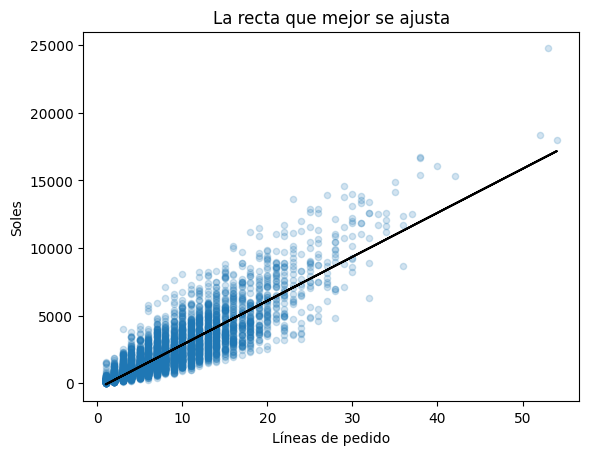

In [6]:
ax = mensual.plot(
    kind="scatter",
    x="lineas",
    y="total",
    alpha=0.2,
    title="La recta que mejor se ajusta",
    xlabel="Líneas de pedido",
    ylabel="Soles",
)
ax.plot(x, modelo.predict(x), color="black")
plt.show()

### Paso 4: predecir, y sus límites

¿Y un cliente con 5 líneas o con 1?

In [7]:
nuevos = pd.DataFrame({"lineas": [5, 1]})

modelo.predict(nuevos).round(1)

array([1210.5,  -91.5])

¡Una compra de **S/ -91.5**! Nadie compra en negativo. Una recta no sabe de negocios: solo sigue su fórmula. Por eso, **mira siempre si la respuesta tiene sentido**.

Hay otro límite. La misma recta sirve para todos, pero los clientes son distintos. Lo veremos en el ejercicio, separando por tipo de cliente.

Y uno más, el más importante: las líneas del mes **no se conocen hasta que el mes termina**. Esta recta explica lo que pasó, pero todavía no sirve para pronosticar. Llegaremos ahí en el episodio 1.4.

## 🤖 Pídeselo a la IA

> *"Tengo una regresión lineal con pendiente 12 y R² de 0.40, que relaciona horas de capacitación con ventas. Explícame qué significa, sin fórmulas, y qué no puedo concluir."*

La IA te ayuda a escribir y entender código, pero **tú debes entender lo que hace**. Revisa cada respuesta antes de usarla, y no pegues datos de tu empresa.

## ✅ Resumen

| En Excel | En Python |
|---|---|
| Gráfico de dispersión | `tabla.plot(kind="scatter", x="a", y="b")` |
| `=PENDIENTE()` (`SLOPE`) | `modelo.coef_` |
| `=INTERSECCION.EJE()` (`INTERCEPT`) | `modelo.intercept_` |
| `=COEFICIENTE.R2()` (`RSQ`) | `modelo.score(x, y)` |
| `=PRONOSTICO.LINEAL()` (`FORECAST.LINEAR`) | `modelo.predict(nuevos)` |
| Línea de tendencia | `ax.plot(x, modelo.predict(x))` |

## 📝 Ahora te toca

Abre [el ejercicio en Colab](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/02-tu-primer-modelo-la-recta/ejercicio.ipynb) y compara las rectas de cada tipo de cliente. Cuando termines, compara con [la solución](https://colab.research.google.com/github/PercyTechX/del-excel-al-ml/blob/main/temporada-1/02-tu-primer-modelo-la-recta/solucion.ipynb).

---

*Del Excel al Machine Learning* · por [Percy Nazario](https://www.linkedin.com/in/percy-nazario/) · [Repositorio](https://github.com/PercyTechX/del-excel-al-ml) · Contenido bajo licencia CC BY 4.0